# 19. What is and is not predicted: horizon, onset threshold and power (development period, exploratory)

In the notebook 17 holdout, pre-onset warning was significant under the primary null but disappeared under the short-shift null that moves alerts by only 4 hours to 1 day. Here I explain that result and check three alternative explanations.

### A. Pre-onset warning by horizon

I test whether "risky days are visible but the moment a crash starts is not".
- As positives I take, in turn, the minutes followed by a crash within 30 minutes–4 hours, 4–12 hours, 12–24 hours and 1–3 days.
- I exclude positives in which the decline has already started (the Kamran-style restriction of notebook 18).
- I compute two AUCs: the overall AUC, which includes the ability to recognize risky periods, and the within-regime AUC, which compares minutes only within the same 24-hour volatility decile and so keeps only information beyond the volatility regime.
- **24-hour realized volatility itself** serves as a baseline score; a model close to this baseline knows only the regime.
- To isolate the clustering of crashes right after a crash (aftershocks), I also report results that exclude the 24 hours after a previous crash.

### B. Onset-threshold sensitivity

This part addresses the objection that "1% is arbitrary".
- I set the onset threshold to 0.5%, 1%, 1.5% and 2% and separate pre-onset warning from in-progress detection again.
- I recompute this both with the notebook 16 alerts under the two null models and with the notebook 18 per-sample AUC.

### C. Power

Here I address the objection that "the effect is not absent, it was just not found".
- I compute the minimum pre-onset excess detectable with 80% power (MDE).
- For the development period it comes from this notebook's null distributions.
- For the 2018–2020 BTC holdout (notebook 11) and the 2018–2019 altcoin holdout (notebook 17), I take it from **the stored null distributions alone** and recompute nothing from holdout data.

This analysis is exploratory. I compute only on the development period (2023-01 to 2026-04), with the frozen 4% models from notebook 16. I record the settings in `19_SPEC.json` and write the results to `horizon_onset_power_v1`.

In [1]:
from pathlib import Path
from collections import deque, defaultdict
import io, os, sys, json, math, time, hashlib, zipfile, warnings, urllib.request, urllib.error
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import binomtest
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
try:
    import pyarrow  # noqa: F401
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'pyarrow'])
try:
    from numba import njit
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', 'numba'])
    from numba import njit
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab: paths below must point to a folder with the same structure.')

DRIVE = Path('/content/drive/MyDrive')
SPOT_BASE = DRIVE / 'btc_lead_cost_results_77months_spot'      # spot results (notebooks 01–07)
FUT_BASE = DRIVE / 'btc_lead_cost_results_77months'            # futures results, read only
BINANCE = 'https://data.binance.vision/data/'
NS = 60 * 10**9
LEAD_MIN = 30; LEAD_MAX = 240; COOLDOWN = 240; COOLDOWN_MIN = 240
B = 240; MONTH_CAP = 20
EVAL_START = '2023-01-01'; EVAL_END = '2026-05-01'

_src = SPOT_BASE / 'cache' / 'DATA_SOURCE.json'
if not _src.is_file() or json.loads(_src.read_text()).get('venue') != 'spot':
    raise RuntimeError(f'Spot cache not found: {_src}. Run notebook 01 first.')
REF_PATH = SPOT_BASE / 'causal_alert_selection_v1' / 'spot_reference.json'
THR_PATH = SPOT_BASE / 'FINAL_risk_adaptive_alert_capacity_v1' / 'spot_frozen_thresholds.json'
for _p in (REF_PATH, THR_PATH):
    if not _p.is_file():
        raise FileNotFoundError(f'Results of notebooks 05 and 06 are required: {_p}')
REF = json.loads(REF_PATH.read_text())
FROZEN = json.loads(THR_PATH.read_text())
assert REF.get('venue') == 'spot' and FROZEN.get('venue') == 'spot'
TH_CAL = float(REF['TH_CAL']); TH_HIGH = float(REF['TH_HIGH']); TH_BUCKET = float(FROZEN['TH_BUCKET'])
print('SPOT cache verified. Frozen spot thresholds:', dict(TH_CAL=TH_CAL, TH_HIGH=TH_HIGH, TH_BUCKET=TH_BUCKET))


def sha256_file(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()
def load_btc_spot():
    px = pd.read_parquet(SPOT_BASE / 'cache' / 'BTCUSDT_1m_regularized.parquet').sort_index()
    sg = pd.read_parquet(SPOT_BASE / 'cache' / 'btc_signals_1m.parquet', columns=['z_vol', 'tsr', 'z_hs']).sort_index()
    for fr in (px, sg):
        assert isinstance(fr.index, pd.DatetimeIndex) and fr.index.tz is not None
        fr.index = fr.index.tz_convert('UTC')
    assert px.index.equals(sg.index), 'price/signal caches must share one 1-minute index'
    assert px.index.is_unique and (np.diff(px.index.asi8) == NS).all()
    return px, sg


def load_catalog(path):
    E = pd.read_csv(path)
    for c in ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']:
        E[c] = pd.to_datetime(E[c], utc=True)
    E = E.sort_values('breach_utc').reset_index(drop=True)
    assert E.event_id.is_unique
    return E


def label_from_catalog(T, E):
    """1 if a 4% breach occurs 30-240 minutes after minute t (same rule as notebooks 04–07)."""
    b = E.breach_utc.astype('int64').to_numpy()
    pos = np.searchsorted(b, T + LEAD_MIN * NS, 'left')
    y = np.zeros(len(T), dtype=np.int8)
    ok = pos < len(b)
    y[ok] = (b[pos[ok]] <= T[ok] + LEAD_MAX * NS).astype(np.int8)
    return y


def ts(s):
    return pd.Timestamp(s, tz='UTC')


def in_period(T, start, end):
    return (T >= ts(start).value) & (T < ts(end).value)


def train_mask(T, valid, year=2021):
    return valid & (T >= ts(f'{year}-01-01').value) & (T < ts(f'{year + 1}-01-01').value - (LEAD_MAX + 5) * NS)


def new_logit():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.2, class_weight='balanced', max_iter=400,
                                                              solver='lbfgs', random_state=17))


def events_between(E, start, end):
    """Evaluation events: breach in [start+4h, end) so every warning window lies inside the period."""
    return E[(E.breach_utc >= ts(start) + pd.Timedelta(minutes=LEAD_MAX)) & (E.breach_utc < ts(end))].reset_index(drop=True)


# --- emit_calendar, as in notebook 05 ---
def emit_calendar(t,eligible,B=240,cap=20,cooldown_min=240):
    t=np.asarray(t,dtype=np.int64)
    eligible=np.asarray(eligible,dtype=bool)
    assert len(t)==len(eligible) and np.all(np.diff(t)>0)
    ids=np.flatnonzero(eligible)
    z=[]; mcount=0; ycount=0; pm=None; py=None; last=-(10**20)
    for k in ids:
        ti=int(t[k]); dt=pd.Timestamp(ti,tz='UTC')
        year=int(dt.year); month=year*12+int(dt.month)
        if year!=py: ycount=0; py=year
        if month!=pm: mcount=0; pm=month
        if ycount>=B or mcount>=cap or ti-last<cooldown_min*NS:continue
        z.append(ti); last=ti; ycount+=1; mcount+=1
    return np.asarray(z,dtype=np.int64)

# --- match_events, as in notebook 05 ---
def match_events(events,alerts):
    alerts=np.sort(np.asarray(alerts,dtype=np.int64))
    out=[];used=set()
    for ev in events.itertuples(index=False):
        breach=ev.breach_utc.value; onset=ev.onset_1pct_utc.value
        left=int(np.searchsorted(alerts,breach-LEAD_MAX*NS,'left'))
        right=int(np.searchsorted(alerts,breach-LEAD_MIN*NS,'right'))
        for j in range(left,right):
            if j not in used:
                used.add(j)
                out.append(dict(event_id=int(ev.event_id),breach_utc=ev.breach_utc,
                                alarm_utc=pd.Timestamp(int(alerts[j]),tz='UTC'),
                                lead_min=(breach-int(alerts[j]))/NS,
                                pre1pct=bool(alerts[j]<onset)))
                break
    return pd.DataFrame(out,columns=['event_id','breach_utc','alarm_utc','lead_min','pre1pct'])

# --- statistics, as in notebook 05 ---
def statistics(events,alerts):
    hits=match_events(events,alerts)
    n=len(alerts);N=len(events)
    return dict(alarms=n,caught=len(hits),before_1pct=int(hits.pre1pct.sum()),
                false_alarms=n-len(hits),recall=len(hits)/N,
                pre_onset_recall=int(hits.pre1pct.sum())/N,
                alert_precision=(len(hits)/n if n else 0))



def cal_fields(t):
    idx = pd.to_datetime(np.asarray(t, dtype='int64'), utc=True)
    years = idx.year.to_numpy().astype(np.int64)
    months = (idx.year.to_numpy() * 12 + idx.month.to_numpy()).astype(np.int64)
    return years, months


@njit(cache=False)
def _calendar_core(t, elig, years, months, B, caps, cooldown_ns):
    # Line-by-line port of emit_calendar with a per-minute monthly cap (caps) so a surge policy can reuse it.
    out = np.empty(len(t), np.int64); k = 0
    mcount = 0; ycount = 0; pm = -1; py = -1; last = -(2**62)
    for i in range(len(t)):
        if not elig[i]:
            continue
        ti = t[i]; yr = years[i]; mo = months[i]
        if yr != py:
            ycount = 0; py = yr
        if mo != pm:
            mcount = 0; pm = mo
        if ycount >= B or mcount >= caps[i] or ti - last < cooldown_ns:
            continue
        out[k] = ti; k += 1; last = ti; ycount += 1; mcount += 1
    return out[:k].copy()


_CAL_CACHE = [None, None]


def emit_calendar_fast(t, eligible, B=240, cap=20, cooldown_min=240, caps=None):
    t = np.asarray(t, dtype=np.int64); eligible = np.asarray(eligible, dtype=bool)
    assert len(t) == len(eligible) and (len(t) < 2 or np.all(np.diff(t) > 0))
    if _CAL_CACHE[0] is t:
        years, months = _CAL_CACHE[1]
    else:
        years, months = cal_fields(t); _CAL_CACHE[0] = t; _CAL_CACHE[1] = (years, months)
    if caps is None:
        caps = np.full(len(t), int(cap), np.int64)
    return _calendar_core(t, eligible, years, months, int(B), np.asarray(caps, np.int64), np.int64(cooldown_min * NS))


def check_fast_calendar(t, s):
    """Stop if the compiled calendar ever differs from the notebook 05 reference implementation."""
    qs = np.unique(np.quantile(s[np.isfinite(s)], [0., .5, .8, .9, .95, .99, .999]))
    for th in qs:
        e = np.isfinite(s) & (s >= th)
        for B_, cap_ in [(240, 20), (60, 5)]:
            if not np.array_equal(emit_calendar(t, e, B=B_, cap=cap_), emit_calendar_fast(t, e, B=B_, cap=cap_)):
                raise AssertionError(f'fast calendar differs from the reference at th={th}, B={B_}')
    return len(qs) * 2


def score_grid(sc):
    Q = np.unique(np.r_[0., np.linspace(.10, .995, 33), .997, .999, .9999, 1.])
    return np.unique(np.r_[np.nextafter(sc.min(), -np.inf), np.quantile(sc, Q), np.nextafter(sc.max(), np.inf)])


def calibrate_calendar(t_cal, s_cal, grid=None, B_=240, cap_=20):
    """Notebook 05 rule: the most 2022 alerts reachable (cap = B), then the fewest raw candidates (strictest)."""
    grid = score_grid(s_cal) if grid is None else grid
    rows = []
    for th in grid:
        e = s_cal >= th
        rows.append((float(th), len(emit_calendar_fast(t_cal, e, B=B_, cap=cap_)), int(e.sum())))
    df = pd.DataFrame(rows, columns=['threshold', 'cal_alerts', 'raw_candidates'])
    best = df[df.cal_alerts == df.cal_alerts.max()].sort_values('raw_candidates').iloc[0]
    return float(best.threshold), int(best.cal_alerts), df


def mcnemar_one_sided(a_only, b_only):
    """P(at least b_only successes | n discordant, p=.5): evidence that B beats A."""
    n = a_only + b_only
    return float(binomtest(b_only, n, .5, alternative='greater').pvalue) if n else 1.0


def mcnemar_two_sided(a_only, b_only):
    n = a_only + b_only
    return float(binomtest(min(a_only, b_only), n, .5).pvalue) if n else 1.0


def paired(events, base_alerts, new_alerts):
    mb = match_events(events, base_alerts); mn = match_events(events, new_alerts)
    hb, hn = set(mb.event_id), set(mn.event_id)
    pb, pn = set(mb.loc[mb.pre1pct, 'event_id']), set(mn.loc[mn.pre1pct, 'event_id'])
    return dict(base_caught=len(hb), new_caught=len(hn), base_only_caught=len(hb - hn), new_only_caught=len(hn - hb),
                p_caught_two_sided=mcnemar_two_sided(len(hb - hn), len(hn - hb)),
                base_pre1pct=len(pb), new_pre1pct=len(pn), base_only_pre1pct=len(pb - pn), new_only_pre1pct=len(pn - pb),
                p_pre1pct_two_sided=mcnemar_two_sided(len(pb - pn), len(pn - pb)),
                p_pre1pct_one_sided_new_better=mcnemar_one_sided(len(pb - pn), len(pn - pb)))
RAW_COLS = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume',
            'trade_count', 'taker_buy_vol', 'taker_buy_quote', 'ignore']


def month_list(first, last):
    return [p.strftime('%Y-%m') for p in pd.period_range(first, last, freq='M')]


def _fetch(url, tries=5):
    last = None
    for k in range(tries):
        try:
            req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
            with urllib.request.urlopen(req, timeout=120) as r:
                return r.read()
        except urllib.error.HTTPError as e:
            if e.code == 404:
                return None
            last = e
        except Exception as e:  # network hiccup: retry
            last = e
        time.sleep(2 ** k)
    raise RuntimeError(f'download failed: {url} ({last})')


def get_archives(prefix, symbol, months, dest, allow_missing=False):
    """Binance public monthly 1m klines (prefix 'spot' or 'futures/um'), SHA-256 checked against .CHECKSUM.
    Already-downloaded files whose hash matches are reused, so an interrupted run resumes."""
    dest = Path(dest); dest.mkdir(parents=True, exist_ok=True)
    rows = []
    for ym in months:
        url = f'{BINANCE}{prefix}/monthly/klines/{symbol}/1m/{symbol}-1m-{ym}.zip'
        z = dest / f'{symbol}-1m-{ym}.zip'
        chk = _fetch(url + '.CHECKSUM')
        if chk is None:
            if allow_missing:
                rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=None, status='not_listed'))
                continue
            raise RuntimeError(f'archive not published: {url}')
        expected = chk.decode().split()[0].strip().lower()
        if z.is_file() and sha256_file(z) == expected:
            status = 'cached'
        else:
            data = _fetch(url)
            if data is None:
                raise RuntimeError(f'archive missing although checksum exists: {url}')
            if hashlib.sha256(data).hexdigest() != expected:
                raise RuntimeError(f'SHA-256 mismatch: {url}')
            part = z.parent / (z.name + '.part'); part.write_bytes(data); part.replace(z)
            status = 'downloaded'
        rows.append(dict(symbol=symbol, venue=prefix, month=ym, url=url, sha256=expected, status=status))
    man = pd.DataFrame(rows)
    print(symbol, prefix, man.status.value_counts().to_dict(), flush=True)
    return man


def parse_kline_zip(path):
    """Header or no header; ms or microsecond timestamps (spot archives switched to microseconds in 2025)."""
    with zipfile.ZipFile(path) as zf:
        members = [m for m in zf.namelist() if m.lower().endswith('.csv')]
        if len(members) != 1:
            raise ValueError(f'expected one CSV in {path}')
        with zf.open(members[0]) as fd:
            x = pd.read_csv(fd, header=None, low_memory=False)
    if str(x.iloc[0, 0]).strip().lower() in ('open_time', 'timestamp'):
        x = x.iloc[1:].reset_index(drop=True)
    if x.shape[1] < 12:
        raise ValueError(f'unexpected kline schema in {path}: {x.shape[1]} columns')
    x = x.iloc[:, :12]; x.columns = RAW_COLS
    number = pd.to_numeric(x.open_time, errors='raise')
    mag = float(number.abs().median())
    unit = 'us' if mag > 1e14 else ('ms' if mag > 1e11 else 's')
    z = x[['open', 'high', 'low', 'close', 'volume', 'taker_buy_vol']].apply(pd.to_numeric, errors='coerce')
    z.index = pd.DatetimeIndex(pd.to_datetime(number, unit=unit, utc=True), name='open_time')
    return z[~z.index.duplicated(keep='last')].sort_index().astype('float64')


def load_archives(manifest, folder):
    parts = [parse_kline_zip(Path(folder) / f"{r.symbol}-1m-{r.month}.zip") for r in manifest.itertuples() if r.status != 'not_listed']
    raw = pd.concat(parts).sort_index(kind='stable')
    return raw[~raw.index.duplicated(keep='last')]


def regularize(raw, start=None, end=None):
    """Notebook 01 gap policy: complete UTC minute grid; missing runs of <=5 minutes get forward-filled OHLC and
    zero volume; longer gaps stay NaN."""
    full = pd.date_range(raw.index.min() if start is None else start, raw.index.max() if end is None else end,
                         freq='min', tz='UTC')
    out = raw.reindex(full); out.index.name = 'open_time'
    missing = ~full.isin(raw.index)
    if missing.any():
        changes = np.r_[True, missing[1:] != missing[:-1]]
        grp = np.cumsum(changes) - 1
        runs = np.bincount(grp[missing], minlength=int(grp.max()) + 1)
        short = missing & (runs[grp] <= 5)
        for c in ['open', 'high', 'low', 'close']:
            out.loc[short, c] = out[c].ffill().loc[short]
        for c in ['volume', 'taker_buy_vol']:
            out.loc[short, c] = 0.0
    return out.astype('float64')


# --- chunked_hs, as in notebook 01 ---
def chunked_hs(close,M=32,K=8,chunk=100_000):
    p=close.to_numpy(dtype=np.float32)
    result=np.full(len(p),np.nan,dtype=np.float64)
    for start in range(M-1,len(p),chunk):
        end=min(len(p),start+chunk)
        w=sliding_window_view(p[start-M+1:end],M)
        zero_mean=w-w.mean(axis=1,keepdims=True)
        result[start:end]=np.abs(np.fft.rfft(zero_mean,axis=1))[:,-K:].mean(axis=1)
        if start==(M-1) or end==len(p): print(f'FFT computation {end:,}/{len(p):,}',flush=True)
    return pd.Series(result,index=close.index)



def compute_spot_features(px, with_hs=True):
    """Exactly the notebook 01 signal formulas (z_hs, z_vol, tsr), float32 like the cache."""
    close = px['close']
    r = np.log(close).diff()
    M = 32; rolling_min = 30 * 1440
    out = {}
    if with_hs:
        hs = chunked_hs(close, M=32, K=8)
        log_hs = np.log1p(hs)
        hs_roll = log_hs.rolling(rolling_min, min_periods=rolling_min // 2)
        out['z_hs'] = ((log_hs - hs_roll.mean().shift(1)) / hs_roll.std().shift(1).replace(0, np.nan)).astype('float32')
    rv = r.rolling(M - 1, min_periods=M - 1).std()
    lrv = np.log(rv.where(rv > 0))
    rv_base = lrv.rolling(rolling_min, min_periods=rolling_min // 2)
    out['z_vol'] = ((lrv - rv_base.mean().shift(1)) / rv_base.std().shift(1).replace(0, np.nan)).astype('float32')
    out['tsr'] = ((px.volume - px.taker_buy_vol) / px.volume.replace(0, np.nan)).clip(0, 1).astype('float32')
    return pd.DataFrame(out, index=px.index)


# --- price_only_catalog, as in notebook 07 ---
def price_only_catalog(close,volume,index,H=240,decline=.04,sustain=5,refractory=1440):
    c=np.asarray(close,dtype=np.float64)
    obs=np.isfinite(c)&(c>0)&np.isfinite(volume)&(np.asarray(volume)>0)
    prior=pd.Series(np.where(obs,c,np.nan)).rolling(H,min_periods=H).max().shift(1).to_numpy()
    raw=obs & np.isfinite(prior) & (c<=(1-decline)*prior)
    fresh=raw & ~np.r_[False,raw[:-1]]
    rows=[];last_confirm=-10**12
    for i in np.flatnonzero(fresh):
        if i+sustain>len(c) or i-last_confirm<refractory:continue
        threshold=(1-decline)*prior[i]
        if not(obs[i:i+sustain].all() and np.all(c[i:i+sustain]<=threshold)):continue
        if i-H<0 or not obs[i-H:i].all():continue
        prev=c[i-H:i];peak_i=int(i-H+np.argmax(prev))
        if peak_i<=last_confirm:continue
        onset_candidates=np.flatnonzero(c[peak_i+1:i+1]<=.99*c[peak_i])
        if not len(onset_candidates):continue
        oi=int(peak_i+1+onset_candidates[0])
        rows.append({'event_id':len(rows)+1,'peak_utc':index[peak_i],
                     'onset_1pct_utc':index[oi], 'breach_utc':index[i],
                     'confirmed_utc':index[i+sustain-1],
                     'peak_close':float(c[peak_i]),'breach_close':float(c[i]),
                     'decline_at_breach_pct':(c[i]/c[peak_i]-1)*100,
                     'peak_to_breach_minutes':i-peak_i,
                     'onset_to_breach_minutes':i-oi})
        last_confirm=i+sustain-1
    df=pd.DataFrame(rows)
    if not len(df):raise RuntimeError('No price-only crash events generated; inspect price history')
    df['year']=pd.DatetimeIndex(df.breach_utc).year
    return df

# Shared with notebook 16 (identical code): VPIN, causal feature set, GBM settings.
REGIME_WINDOW_D = 30; RV_WINDOW = 1440; VPIN_BUCKETS_PER_DAY = 50; VPIN_WINDOW = 50; VPIN_LOOKBACK_D = 30
GBM_PARAMS = dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=200, l2_regularization=1.0,
                  class_weight='balanced', early_stopping=False, random_state=17)
FEATS = ['z_vol', 'tsr', 'z_hs', 'ret_5', 'ret_15', 'ret_60', 'ret_240', 'rv_15', 'rv_60', 'rv_240', 'rv_ratio_15_240',
         'dd_240', 'dd_1440', 'vol_intensity_15', 'sell_ratio_15', 'sell_ratio_60', 'vpin']

@njit(cache=False)
def _vpin_core(vol, buy, bucket, n_win):
    out = np.full(len(vol), np.nan); ring = np.zeros(n_win); k = 0; run = 0.0; cv = 0.0; cb = 0.0
    for i in range(len(vol)):
        v = vol[i]; b = buy[i]
        if not (v == v) or not (b == b) or v < 0:
            v = 0.0; b = 0.0
        cv += v; cb += min(max(b, 0.0), v)
        bs = bucket[i]
        if bs == bs and bs > 0 and cv >= bs:
            imb = abs(2.0 * cb - cv) / cv
            j = k % n_win; run += imb - ring[j]; ring[j] = imb; k += 1; cv = 0.0; cb = 0.0
        if k >= n_win:
            out[i] = run / n_win
    return out


def vpin_series(px):
    vol = px.volume.to_numpy(float); buy = px.taker_buy_vol.to_numpy(float)
    daily = px.volume.groupby(px.index.floor('D')).sum()
    size = (daily.rolling(VPIN_LOOKBACK_D, min_periods=VPIN_LOOKBACK_D).mean().shift(1) / VPIN_BUCKETS_PER_DAY)
    bucket = size.reindex(px.index.floor('D')).to_numpy(float)
    return _vpin_core(vol, buy, bucket, VPIN_WINDOW)


def causal_features(px, sg):
    c = px.close.astype(float); lc = np.log(c); r = lc.diff(); vol = px.volume.astype(float); sell = vol - px.taker_buy_vol.astype(float)
    F = pd.DataFrame(index=px.index)
    F['z_vol'] = sg.z_vol.astype(float); F['tsr'] = sg.tsr.astype(float); F['z_hs'] = sg.z_hs.astype(float)
    for k in (5, 15, 60, 240):
        F[f'ret_{k}'] = lc - lc.shift(k)
    for k in (15, 60, 240):
        F[f'rv_{k}'] = r.rolling(k, min_periods=k // 2).std()
    F['rv_ratio_15_240'] = F.rv_15 / F.rv_240
    F['dd_240'] = 1 - c / c.rolling(240, min_periods=120).max()
    F['dd_1440'] = 1 - c / c.rolling(1440, min_periods=720).max()
    F['vol_intensity_15'] = vol.rolling(15, min_periods=8).sum() / (vol.rolling(1440, min_periods=720).sum() / 96)
    F['sell_ratio_15'] = sell.rolling(15, min_periods=8).sum() / vol.rolling(15, min_periods=8).sum()
    F['sell_ratio_60'] = sell.rolling(60, min_periods=30).sum() / vol.rolling(60, min_periods=30).sum()
    F['vpin'] = vpin_series(px)
    return F.replace([np.inf, -np.inf], np.nan).astype('float32')
# Shared by notebooks 18 and 19: exact block-bootstrap AUC decomposition.
def week_pairs(sp, wp, sn, wn):
    """C[k, l] = over positives in block k, the number of negatives in block l with a lower score (+0.5 per tie).
    With block multiplicities w from the bootstrap, the AUC is w'Cw / ((w'P)(w'N)); w = 1 gives the ordinary AUC."""
    C = np.zeros((N_WEEKS, N_WEEKS))
    if len(sp) == 0 or len(sn) == 0:
        return C
    o = np.lexsort((sn, wn)); sn = sn[o]; wn = wn[o]
    bounds = np.searchsorted(wn, np.arange(N_WEEKS + 1), 'left')
    for l in range(N_WEEKS):
        a, b = bounds[l], bounds[l + 1]
        if a == b:
            continue
        seg = sn[a:b]; lo = np.searchsorted(seg, sp, 'left'); hi = np.searchsorted(seg, sp, 'right')
        C[:, l] = np.bincount(wp, weights=lo + 0.5 * (hi - lo), minlength=N_WEEKS)
    return C


def _ratio(a, b):
    return a / b if b > 0 else np.nan


STAT_KEYS = ['auc_standard', 'auc_pre', 'auc_in', 'share_in', 'diff_standard_minus_pre', 'in_share_of_excess', 'auc_calm',
             'auc_standard_within_regime', 'auc_pre_within_regime', 'auc_in_within_regime']


def make_parts(sm, code, calm, wk, dec):
    neg = code == 0; pre = code == 1; inn = code == 2; cnt = lambda k: np.bincount(wk[k], minlength=N_WEEKS).astype(float)
    P = dict(C_pre=week_pairs(sm[pre], wk[pre], sm[neg], wk[neg]), C_in=week_pairs(sm[inn], wk[inn], sm[neg], wk[neg]),
             C_calm=week_pairs(sm[(code > 0) & calm], wk[(code > 0) & calm], sm[neg & calm], wk[neg & calm]),
             P_pre=cnt(pre), P_in=cnt(inn), N=cnt(neg), P_calm=cnt((code > 0) & calm), N_calm=cnt(neg & calm),
             Cs_pre=np.zeros((N_WEEKS, N_WEEKS)), Cs_in=np.zeros((N_WEEKS, N_WEEKS)), Pq_pre=[], Pq_in=[], Nq=[])
    for q in range(10):
        kq = dec == q; nq = neg & kq; pq = pre & kq; iq = inn & kq
        P['Cs_pre'] += week_pairs(sm[pq], wk[pq], sm[nq], wk[nq]); P['Cs_in'] += week_pairs(sm[iq], wk[iq], sm[nq], wk[nq])
        P['Pq_pre'].append(cnt(pq)); P['Pq_in'].append(cnt(iq)); P['Nq'].append(cnt(nq))
    for k in ('Pq_pre', 'Pq_in', 'Nq'):
        P[k] = np.array(P[k])
    return P


def stats_from(P, w):
    q = lambda C: w @ C @ w
    Wn = w @ P['N']; Wp = w @ P['P_pre']; Wi = w @ P['P_in']; sp = q(P['C_pre']); si = q(P['C_in'])
    std = _ratio(sp + si, (Wp + Wi) * Wn); pre = _ratio(sp, Wp * Wn); inn = _ratio(si, Wi * Wn); pi = _ratio(Wi, Wp + Wi)
    nq = P['Nq'] @ w; pq = P['Pq_pre'] @ w; iq = P['Pq_in'] @ w; ssp = q(P['Cs_pre']); ssi = q(P['Cs_in'])
    return dict(auc_standard=std, auc_pre=pre, auc_in=inn, share_in=pi, diff_standard_minus_pre=std - pre,
                in_share_of_excess=_ratio(pi * (inn - 0.5), std - 0.5) if np.isfinite(inn) else 0.0,
                auc_calm=_ratio(q(P['C_calm']), (w @ P['P_calm']) * (w @ P['N_calm'])),
                auc_standard_within_regime=_ratio(ssp + ssi, ((pq + iq) * nq).sum()),
                auc_pre_within_regime=_ratio(ssp, (pq * nq).sum()), auc_in_within_regime=_ratio(ssi, (iq * nq).sum()))
import joblib

OUT = SPOT_BASE / 'horizon_onset_power_v1'; OUT.mkdir(parents=True, exist_ok=True)
M16 = SPOT_BASE / 'methods_definitions_v1'
HOLD11 = SPOT_BASE / 'HOLDOUT_2018_2020_confirmatory_v1'; HOLD17 = SPOT_BASE / 'HOLDOUT17_multicoin_2018_2019_v1'
DNAME, DCL = '4pct', 0.04
METHODS = ['M0_VF_logit', 'M1_vol_threshold', 'M2_VPIN', 'M3_GBM_rich']
SCORE_NAMES = METHODS + ['B0_RV24h_baseline']
BANDS = {'30m-4h': (30, 240), '4h-12h': (240, 720), '12h-24h': (720, 1440), '1d-3d': (1440, 4320)}
AFTERMATH_MIN = 1440; ONSETS = (0.005, 0.01, 0.015, 0.02)
N_BOOT = 500; N_NULL = 1000; SEED = 20261102; BLOCK_DAYS = 7; Z80 = 0.8416; Z95 = 1.6449
EVAL_LAST = ts(EVAL_END).value - (max(b for _, b in BANDS.values()) + 5) * NS

for _p in [M16 / 'METHODS_FROZEN.json', M16 / 'METHODS_SPEC.json', M16 / '4_methods_definitions_nulls.csv',
           HOLD11 / 'HOLDOUT_EVALUATED.lock', HOLD11 / 'HOLDOUT_RESULTS.json', HOLD11 / 'H1_circular_shift_null.csv',
           HOLD17 / 'HOLDOUT17_EVALUATED.lock', HOLD17 / 'H17_all_tests.csv']:
    if not _p.is_file():
        raise FileNotFoundError(f'Required earlier result not found: {_p}')
FROZEN16 = json.loads((M16 / 'METHODS_FROZEN.json').read_text()); SPEC16 = json.loads((M16 / 'METHODS_SPEC.json').read_text())
if sha256_file(M16 / 'METHODS_SPEC.json') != FROZEN16['spec_sha256'] or SPEC16['gbm_params'] != GBM_PARAMS or SPEC16['gbm_features'] != FEATS:
    raise RuntimeError('GUARD FAIL: notebook-16 spec/settings differ')

SPEC = {'title': 'Horizon profile, onset-threshold sensitivity and power (dev 2023-01..2026-04, exploratory)',
        'models': 'notebook-16 frozen 4% models (M0 coefficient guard, M3 SHA-256 guard), M1 z_vol, M2 VPIN; baseline B0 = trailing 24h realized volatility',
        'A_horizon': {'bands_min': BANDS, 'label': 'a 4% catalog breach in [t+a, t+b]', 'pre_onset_only': 'positives with t >= 1% onset of the labeling event excluded (Kamran-style)',
                      'within_regime': 'pairs within the same 24h realized-volatility decile', 'aftermath_variant': f'drop minutes within {AFTERMATH_MIN} min after any breach',
                      'evaluation_minutes': f'{EVAL_START} to {EVAL_END} minus {max(b for _, b in BANDS.values()) + 5} min (common to all bands)'},
        'B_onset': {'thresholds': ONSETS, 'onset_rule': 'first minute after the peak with close <= (1-x) * peak close (catalog rule at x = 1%)',
                    'alerts': 'notebook-16 dev alarms, 4%', 'nulls': f'circular >= 7d and regime-matched (24h-RV decile, +-30d), {N_NULL} draws each',
                    'per_sample': 'notebook-18 L1 decomposition with the in-decline split at each threshold'},
        'C_power': {'rule': 'minimum excess detectable with 80% power at one-sided alpha 0.05 under a shift alternative; exact (null q95 - q20) when draws exist, '
                            'normal approximation 2.486*sd otherwise (sd from stored q05/q95 or p95)',
                    'holdouts': 'stored summaries only (notebook 11 H1 null draws; notebook 17 H17_all_tests.csv); no holdout data are re-read or re-evaluated'},
        'bootstrap': f'{N_BOOT} resamples of {BLOCK_DAYS}-day blocks', 'seed': SEED, 'notebook16_spec_sha256': FROZEN16['spec_sha256']}
_raw = (json.dumps(SPEC, indent=2, sort_keys=True, default=str) + '\n').encode()
_sp = OUT / '19_SPEC.json'
if _sp.exists() and _sp.read_bytes() != _raw:
    _sp.rename(OUT / f'19_SPEC.replaced_{pd.Timestamp.now(tz="UTC"):%Y%m%dT%H%M%S}.json')
_sp.write_bytes(_raw); SPEC_SHA = hashlib.sha256(_raw).hexdigest()
print('Output:', OUT, '| spec sha256', SPEC_SHA[:16])

Mounted at /content/drive
SPOT cache verified. Frozen spot thresholds: {'TH_CAL': 0.6698990591069133, 'TH_HIGH': 0.6864782740093911, 'TH_BUCKET': 0.7166067355142407}
Output: /content/drive/MyDrive/btc_lead_cost_results_77months_spot/horizon_onset_power_v1 | spec sha256 b8dc6d6e0c30fa5e


## 1. Data, events and scores

In [2]:
t_ = time.time()
px, sg = load_btc_spot()
F = causal_features(px, sg)
T = px.index.asi8; close = px.close.to_numpy(float); volume = px.volume.to_numpy(float)
v_ = sg.z_vol.to_numpy(float); f_ = sg.tsr.to_numpy(float); h_ = sg.z_hs.to_numpy(float)
VALID = (np.isfinite(close) & (close > 0) & np.isfinite(volume) & (volume > 0) & np.isfinite(v_) & np.isfinite(f_) & np.isfinite(h_) & (f_ >= 0) & (f_ <= 1))
EVM = VALID & (T >= ts(EVAL_START).value) & (T < EVAL_LAST)
DD240 = F.dd_240.to_numpy(float); CALM = np.isfinite(DD240) & (DD240 < DCL / 4)
_lc = np.log(np.where(np.isfinite(close) & (close > 0), close, np.nan))
RV = pd.Series(_lc).diff().rolling(RV_WINDOW, min_periods=RV_WINDOW // 2).std().to_numpy()
DEC = np.full(len(T), -1, np.int64); _okr = EVM & np.isfinite(RV)
DEC[_okr] = np.minimum((pd.Series(RV[_okr]).rank(pct=True).to_numpy() * 10).astype(int), 9)
WEEK = np.where(EVM, (T - ts(EVAL_START).value) // (BLOCK_DAYS * 1440 * NS), -1).astype(np.int64)
N_WEEKS = int(WEEK[EVM].max()) + 1

TCOLS = ['peak_utc', 'onset_1pct_utc', 'breach_utc', 'confirmed_utc']
E_ref = load_catalog(SPOT_BASE / 'event_definition_eligibility_audit' / 'price_only_event_catalog.csv')
E = price_only_catalog(close, volume, px.index, decline=DCL)
for c_ in TCOLS:
    E[c_] = pd.to_datetime(E[c_], utc=True)
E = E.sort_values('breach_utc').reset_index(drop=True)
if len(E) != len(E_ref) or any(not np.array_equal(E[c_].astype('int64').to_numpy(), E_ref[c_].astype('int64').to_numpy()) for c_ in TCOLS):
    raise RuntimeError('GUARD FAIL: 4% catalog differs from the notebook-2 catalog')
BR = E.breach_utc.astype('int64').to_numpy()


def onset_at(Ev, x):
    """First minute after the peak with close <= (1-x) * peak close (the catalog rule, generalised from x = 1%)."""
    pk = ((Ev.peak_utc.astype('int64').to_numpy() - T[0]) // NS).astype(np.int64)
    br = ((Ev.breach_utc.astype('int64').to_numpy() - T[0]) // NS).astype(np.int64)
    out = np.empty(len(Ev), np.int64)
    for k, (p, q) in enumerate(zip(pk, br)):
        hit = np.flatnonzero(close[p + 1:q + 1] <= (1 - x) * close[p])
        out[k] = T[p + 1 + hit[0]] if len(hit) else T[q]
    return out


ONSET_ALL = {x: onset_at(E, x) for x in ONSETS}
if not np.array_equal(ONSET_ALL[0.01], E.onset_1pct_utc.astype('int64').to_numpy()):
    raise RuntimeError('GUARD FAIL: generalised onset rule does not reproduce the 1% catalog onset')

# scores (notebook-16 frozen 4% models)
y_l1 = label_from_catalog(T, E); tr = train_mask(T, VALID)
Xl = F[['z_vol', 'tsr']].to_numpy(float); okl = tr & np.isfinite(Xl).all(axis=1)
cfg0 = FROZEN16['configs'][f'M0_VF_logit|{DNAME}']
m0 = new_logit().fit(Xl[okl], y_l1[okl])
if not (np.allclose(m0[-1].coef_.ravel(), cfg0['coef'], rtol=1e-6, atol=1e-9) and np.isclose(m0[-1].intercept_[0], cfg0['intercept'], rtol=1e-6, atol=1e-9)):
    raise RuntimeError('GUARD FAIL: M0 refit differs from notebook 16')
cfg3 = FROZEN16['configs'][f'M3_GBM_rich|{DNAME}']; mp = SPOT_BASE / cfg3['model_file']
if sha256_file(mp) != cfg3['model_sha256']:
    raise RuntimeError('GUARD FAIL: notebook-16 GBM file SHA-256 differs')
g3 = joblib.load(mp)
IDX = np.flatnonzero(EVM); S = {}
s = np.full(len(T), np.nan); okp = EVM & np.isfinite(Xl).all(axis=1); s[okp] = m0.predict_proba(Xl[okp])[:, 1]; S['M0_VF_logit'] = s
S['M1_vol_threshold'] = np.where(VALID, F.z_vol.to_numpy(float), np.nan)
S['M2_VPIN'] = np.where(VALID, F.vpin.to_numpy(float), np.nan)
s = np.full(len(T), np.nan); s[IDX] = g3.predict_proba(F[FEATS].to_numpy(np.float32)[IDX])[:, 1]; S['M3_GBM_rich'] = s
S['B0_RV24h_baseline'] = np.where(VALID, RV, np.nan)
print(f'evaluation minutes {int(EVM.sum()):,}, {N_WEEKS} blocks; catalog and onset rule verified; models verified; {time.time() - t_:.0f}s')


def eval_case(s, y, inn, base, seed, guard=False):
    m = base & np.isfinite(s) & (DEC >= 0)
    code = np.where(y[m] == 1, np.where(inn[m], 2, 1), 0).astype(np.int64)
    P = make_parts(s[m], code, CALM[m], WEEK[m], DEC[m])
    point = stats_from(P, np.ones(N_WEEKS))
    point.update(n_pre=int((code == 1).sum()), n_in=int((code == 2).sum()), n_neg=int((code == 0).sum()))
    if guard:
        from sklearn.metrics import roc_auc_score
        keep = code != 2
        if abs(roc_auc_score((code[keep] > 0).astype(int), s[m][keep]) - point['auc_pre']) > 1e-9:
            raise RuntimeError('GUARD FAIL: block-pair AUC differs from sklearn')
        print('PASS: block-pair AUC equals sklearn')
    rng = np.random.default_rng(seed); boot = {k: np.empty(N_BOOT) for k in STAT_KEYS}
    for i in range(N_BOOT):
        r = stats_from(P, np.bincount(rng.integers(0, N_WEEKS, N_WEEKS), minlength=N_WEEKS).astype(float))
        for k in STAT_KEYS:
            boot[k][i] = r[k]
    for k in STAT_KEYS:
        lo, hi = np.nanpercentile(boot[k], [2.5, 97.5]) if np.isfinite(boot[k]).any() else (np.nan, np.nan)
        point[f'{k}_lo'] = float(lo); point[f'{k}_hi'] = float(hi)
    return point

evaluation minutes 1,746,532, 174 blocks; catalog and onset rule verified; models verified; 73s


## A. Pre-onset warning by horizon

PASS: block-pair AUC equals sklearn
band 30m-4h done (29s)
band 4h-12h done (62s)
band 12h-24h done (104s)
band 1d-3d done (224s)


band,30m-4h,4h-12h,12h-24h,1d-3d
score,,,,
B0_RV24h_baseline,0.709,0.729,0.708,0.629
M0_VF_logit,0.673,0.588,0.619,0.560
M1_vol_threshold,0.674,0.588,0.619,0.560
M2_VPIN,0.437,0.455,0.452,0.440
M3_GBM_rich,0.654,0.618,0.640,0.603


band,30m-4h,4h-12h,12h-24h,1d-3d
score,,,,
B0_RV24h_baseline,0.514,0.490,0.538,0.520
M0_VF_logit,0.593,0.473,0.519,0.499
M1_vol_threshold,0.594,0.473,0.520,0.499
M2_VPIN,0.464,0.489,0.481,0.457
M3_GBM_rich,0.547,0.497,0.538,0.551


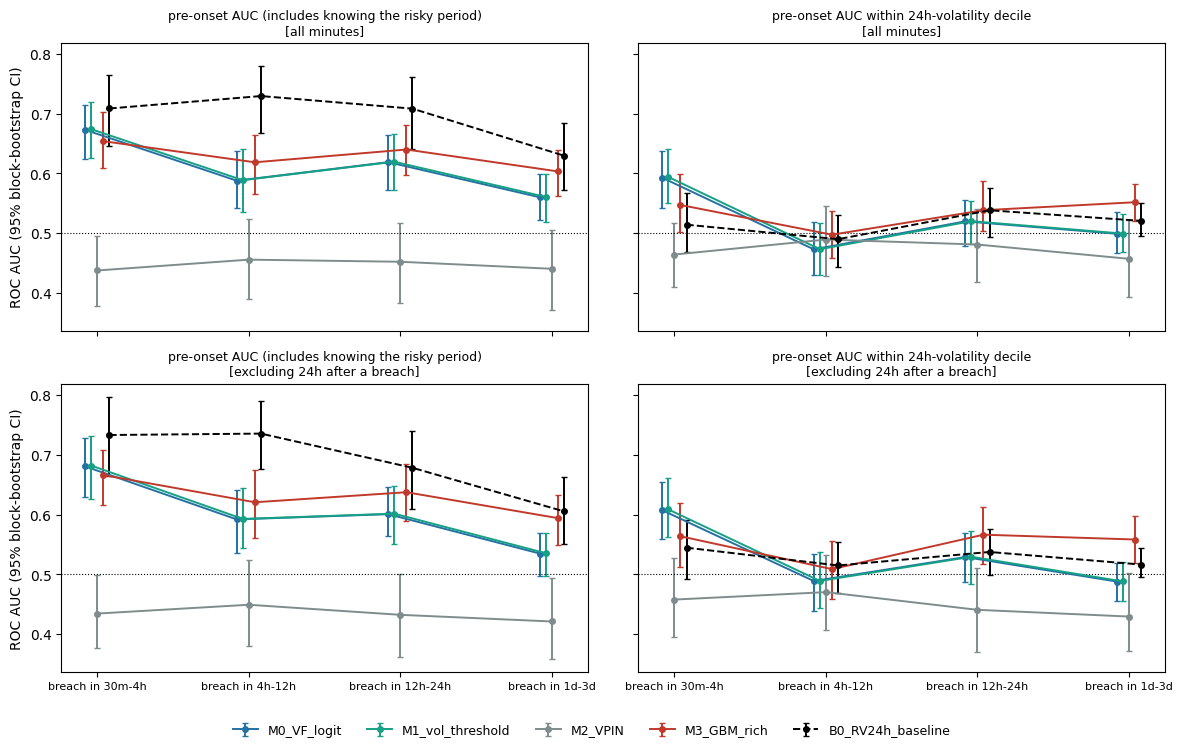

In [3]:
last = np.searchsorted(BR, T, 'right') - 1
AFTER = (last >= 0) & (T - BR[np.clip(last, 0, None)] < AFTERMATH_MIN * NS)
O1 = ONSET_ALL[0.01]
rows = []; t_ = time.time(); ci = 0
for bname, (lo, hi) in BANDS.items():
    pos = np.searchsorted(BR, T + lo * NS, 'left'); ok = pos < len(BR)
    y = np.zeros(len(T), np.int8); y[ok] = BR[pos[ok]] <= T[ok] + hi * NS
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= O1[pos[ok]]; inn &= (y == 1)
    for variant, base in [('all minutes', EVM), ('excluding 24h after a breach', EVM & ~AFTER)]:
        for sname in SCORE_NAMES:
            r = eval_case(S[sname], y, inn, base, SEED + ci, guard=(ci == 0)); ci += 1
            rows.append(dict(band=bname, lead_min_from=lo, lead_min_to=hi, variant=variant, score=sname, prevalence=r['n_pre'] / (r['n_pre'] + r['n_neg']), **r))
    print(f'band {bname} done ({time.time() - t_:.0f}s)', flush=True)
HP = pd.DataFrame(rows); HP.to_csv(OUT / '1_horizon_profile.csv', index=False)
display(HP[HP.variant == 'all minutes'].pivot(index='score', columns='band', values='auc_pre')[list(BANDS)].round(3))
display(HP[HP.variant == 'all minutes'].pivot(index='score', columns='band', values='auc_pre_within_regime')[list(BANDS)].round(3))

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharex=True, sharey=True)
colors = {'M0_VF_logit': '#2471a3', 'M1_vol_threshold': '#16a085', 'M2_VPIN': '#7f8c8d', 'M3_GBM_rich': '#c0392b', 'B0_RV24h_baseline': '#000000'}
xb = np.arange(len(BANDS))
for i, variant in enumerate(['all minutes', 'excluding 24h after a breach']):
    for j, (k, ttl) in enumerate([('auc_pre', 'pre-onset AUC (includes knowing the risky period)'), ('auc_pre_within_regime', 'pre-onset AUC within 24h-volatility decile')]):
        ax = axes[i, j]
        for sname in SCORE_NAMES:
            g = HP[(HP.variant == variant) & (HP.score == sname)].set_index('band').reindex(list(BANDS))
            ax.errorbar(xb + 0.04 * (SCORE_NAMES.index(sname) - 2), g[k], yerr=[g[k] - g[f'{k}_lo'], g[f'{k}_hi'] - g[k]], color=colors[sname],
                        marker='o', ms=4, capsize=2, lw=1.4, ls='--' if sname.startswith('B0') else '-', label=sname)
        ax.axhline(0.5, color='k', lw=0.8, ls=':'); ax.set_title(f'{ttl}\n[{variant}]', fontsize=9)
        ax.set_xticks(xb); ax.set_xticklabels([f'breach in {b}' for b in BANDS], fontsize=8)
axes[0, 0].set_ylabel('ROC AUC (95% block-bootstrap CI)'); axes[1, 0].set_ylabel('ROC AUC (95% block-bootstrap CI)')
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='lower center', ncol=5, fontsize=9, frameon=False)
plt.tight_layout(rect=[0, 0.05, 1, 1]); plt.savefig(OUT / '1_horizon_profile.png', dpi=140); plt.show()

## B. Onset-threshold sensitivity

I match alerts to events as in notebook 16 (the earliest unused alert in the window 30–240 minutes before the crash). Changing the onset threshold changes only whether a matched alert counts as pre-onset warning or in-progress detection.

M0_VF_logit: nulls done (15s)
M1_vol_threshold: nulls done (30s)
M2_VPIN: nulls done (45s)
M3_GBM_rich: nulls done (60s)


onset_threshold,0.005,0.010,0.015,0.020
method,,,,
M0_VF_logit,0.618,0.447,0.444,0.200
M1_vol_threshold,0.599,0.492,0.417,0.269
M2_VPIN,0.389,0.132,-0.163,-0.207
M3_GBM_rich,1.073,0.952,0.418,0.149


p_post                        p_pre  \
null                             circular >=7d regime-matched circular >=7d   
method           onset_threshold                                              
M0_VF_logit      0.005                  0.0010         0.0010        0.0010   
                 0.010                  0.0010         0.0010        0.0010   
                 0.015                  0.0010         0.0010        0.0010   
                 0.020                  0.0020         0.0010        0.0010   
M1_vol_threshold 0.005                  0.0010         0.0010        0.0020   
                 0.010                  0.0010         0.0010        0.0010   
                 0.015                  0.0010         0.0010        0.0010   
                 0.020                  0.0010         0.0010        0.0010   
M2_VPIN          0.005                  0.2917         0.2637        0.0819   
                 0.010                  0.4376         0.4605        0.0440   
                 0.015                  0.6933         0.7612        0.0170   
                 0.020                  0.8102         0.8731        0.0290   
M3_GBM_rich      0.005                  0.0010         0.0010        0.4735   
                 0.010                  0.0010         0.0010        0.1858   
                 0.015                  0.0020         0.0030        0.0020   
                 0.020                  0.0360         0.1459        0.0010   

                                                 
null                             regime-matched  
method           onset_threshold                 
M0_VF_logit      0.005                   0.0010  
                 0.010                   0.0010  
                 0.015                   0.0010  
                 0.020                   0.0010  
M1_vol_threshold 0.005                   0.0010  
                 0.010                   0.0010  
                 0.015                   0.0010  
                 0.020                   0.0010  
M2_VPIN          0.005                   0.1518  
                 0.010                   0.0839  
                 0.015                   0.0380  
                 0.020                   0.0350  
M3_GBM_rich      0.005                   0.7582  
                 0.010                   0.4486  
                 0.015                   0.0010  
                 0.020                   0.0010

onset_threshold,0.005,0.010,0.015,0.020
score,,,,
B0_RV24h_baseline,0.587,0.505,0.413,0.309
M0_VF_logit,0.714,0.615,0.512,0.365
M1_vol_threshold,0.712,0.614,0.511,0.363
M2_VPIN,NaN,NaN,NaN,NaN
M3_GBM_rich,0.748,0.646,0.547,0.394


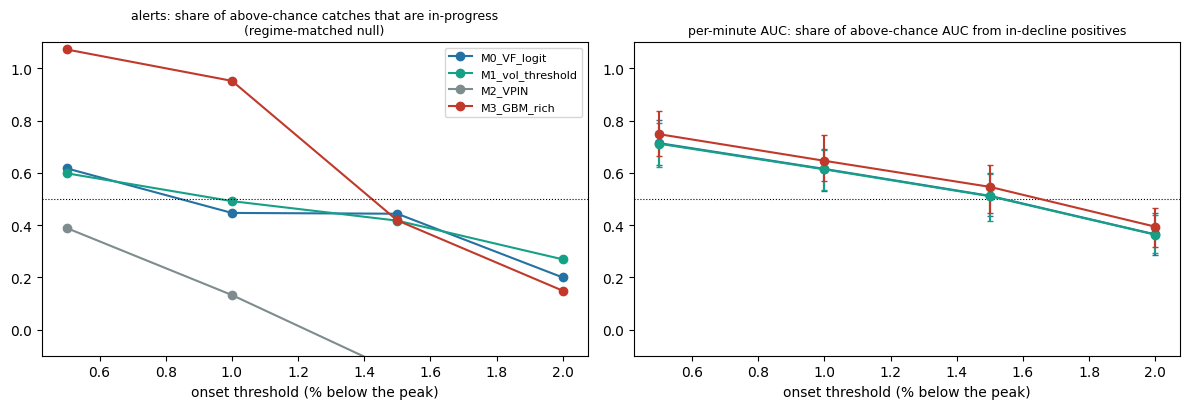

In [4]:
EV = events_between(E, EVAL_START, EVAL_END)
EV_ON = {x: onset_at(EV, x) for x in ONSETS}
eid_pos = {int(e): k for k, e in enumerate(EV.event_id)}
gap = {x: (EV.breach_utc.astype('int64').to_numpy() - EV_ON[x]) / NS for x in ONSETS}
ALERTS = {}
for mname in METHODS:
    a = np.sort(pd.to_datetime(pd.read_csv(M16 / f'alarms_{mname}_{DNAME}.csv').alarm_utc, utc=True).astype('int64').to_numpy())
    if len(a) != FROZEN16['configs'][f'{mname}|{DNAME}']['dev_alerts']:
        raise RuntimeError(f'GUARD FAIL: notebook-16 alarms for {mname} changed')
    ALERTS[mname] = a


def counts_multi(a):
    m = match_events(EV, np.sort(np.asarray(a, np.int64)))
    if not len(m):
        return {x: (0, 0) for x in ONSETS}, 0
    k = np.array([eid_pos[int(e)] for e in m.event_id]); al = m.alarm_utc.astype('int64').to_numpy()
    out = {}
    for x in ONSETS:
        pre = int((al < EV_ON[x][k]).sum()); out[x] = (pre, len(m) - pre)
    return out, len(m)


t0_ = ts(EVAL_START).value; L_ = (ts(EVAL_END).value - t0_) // NS
okd = in_period(T, EVAL_START, EVAL_END) & np.isfinite(RV)
TT = T[okd]; DDq = np.minimum((pd.Series(RV[okd]).rank(pct=True).to_numpy() * 10).astype(int), 9)
_order = np.lexsort((TT, DDq)); PP = TT[_order]; DS = DDq[_order]
STARTS = np.searchsorted(DS, np.arange(10), 'left'); ENDS = np.searchsorted(DS, np.arange(10), 'right')


def draw_circular(a, rng):
    d = int(rng.integers(7 * 1440, L_ - 7 * 1440))
    return np.sort(t0_ + (a - t0_ + d * NS) % (L_ * NS))


def draw_regime(a, rng, W=30 * 1440 * NS):
    j = np.clip(np.searchsorted(TT, a, 'right') - 1, 0, len(TT) - 1); ad = DDq[j]
    lo = np.array([STARTS[q] + np.searchsorted(PP[STARTS[q]:ENDS[q]], ti - W, 'left') for ti, q in zip(a, ad)])
    hi = np.array([STARTS[q] + np.searchsorted(PP[STARTS[q]:ENDS[q]], ti + W, 'right') for ti, q in zip(a, ad)])
    c = PP[lo + (rng.random(len(a)) * (hi - lo)).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    for _ in range(20):
        if not bad.any():
            break
        c[bad] = PP[lo[bad] + (rng.random(int(bad.sum())) * (hi[bad] - lo[bad])).astype(np.int64)]; bad = np.abs(c - a) < LEAD_MAX * NS
    return np.sort(c)


R16 = pd.read_csv(M16 / '4_methods_definitions_nulls.csv')
NULLD = {}; brow = []; t_ = time.time()
for mi, mname in enumerate(METHODS):
    a = ALERTS[mname]; obs, caught = counts_multi(a)
    r16 = R16[(R16.method == mname) & (R16.definition == DNAME)].iloc[0]
    if (obs[0.01][0], obs[0.01][1], caught) != (int(r16.pre), int(r16.post), int(r16.caught)):
        raise RuntimeError(f'GUARD FAIL: {mname} counts at 1% differ from notebook 16')
    for ni, (nname, drawer) in enumerate([('circular >=7d', draw_circular), ('regime-matched', draw_regime)]):
        rng = np.random.default_rng(SEED + 100 * mi + ni)
        pre_d = {x: np.empty(N_NULL) for x in ONSETS}; post_d = {x: np.empty(N_NULL) for x in ONSETS}; cau_d = np.empty(N_NULL)
        for i in range(N_NULL):
            c, n = counts_multi(drawer(a, rng)); cau_d[i] = n
            for x in ONSETS:
                pre_d[x][i], post_d[x][i] = c[x]
        NULLD[(mname, nname)] = dict(pre=pre_d, post=post_d, caught=cau_d)
        for x in ONSETS:
            po, qo = obs[x]
            brow.append(dict(method=mname, onset_threshold=x, null=nname, events=len(EV),
                             pre_eligible_events=int((gap[x] < LEAD_MAX).sum()), post_eligible_events=int((gap[x] >= LEAD_MIN).sum()),
                             caught=caught, pre=po, post=qo, pre_null_mean=float(pre_d[x].mean()), post_null_mean=float(post_d[x].mean()),
                             caught_null_mean=float(cau_d.mean()),
                             p_pre=(1 + int((pre_d[x] >= po).sum())) / (N_NULL + 1), p_post=(1 + int((post_d[x] >= qo).sum())) / (N_NULL + 1),
                             post_share_of_excess_caught=((qo - post_d[x].mean()) / (caught - cau_d.mean())) if caught - cau_d.mean() > 0 else np.nan))
    print(f'{mname}: nulls done ({time.time() - t_:.0f}s)', flush=True)
OB = pd.DataFrame(brow); OB.to_csv(OUT / '2_onset_alerts.csv', index=False)
display(OB[OB.null == 'regime-matched'].pivot(index='method', columns='onset_threshold', values='post_share_of_excess_caught').round(3))
display(OB.pivot_table(index=['method', 'onset_threshold'], columns='null', values=['p_pre', 'p_post']).round(4))

prow = []
for x in ONSETS:
    pos = np.searchsorted(BR, T + LEAD_MIN * NS, 'left'); ok = pos < len(BR)
    inn = np.zeros(len(T), bool); inn[ok] = T[ok] >= ONSET_ALL[x][pos[ok]]; inn &= (y_l1 == 1)
    for sname in SCORE_NAMES:
        r = eval_case(S[sname], y_l1, inn, EVM, SEED + 5000 + ci); ci += 1
        prow.append(dict(onset_threshold=x, score=sname, **{k: r[k] for k in ['n_pre', 'n_in', 'share_in', 'auc_standard', 'auc_pre', 'auc_pre_lo', 'auc_pre_hi',
                                                                               'auc_in', 'in_share_of_excess', 'in_share_of_excess_lo', 'in_share_of_excess_hi', 'auc_pre_within_regime']}))
OP = pd.DataFrame(prow); OP.to_csv(OUT / '2_onset_per_sample.csv', index=False)
display(OP.pivot(index='score', columns='onset_threshold', values='in_share_of_excess').round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for mname in METHODS:
    g = OB[(OB.method == mname) & (OB.null == 'regime-matched')]
    ax[0].plot(g.onset_threshold * 100, g.post_share_of_excess_caught, marker='o', color=colors[mname], label=mname)
    h = OP[OP.score == mname]
    ax[1].errorbar(h.onset_threshold * 100, h.in_share_of_excess, yerr=[h.in_share_of_excess - h.in_share_of_excess_lo, h.in_share_of_excess_hi - h.in_share_of_excess],
                   marker='o', capsize=2, color=colors[mname], label=mname)
ax[0].set_title('alerts: share of above-chance catches that are in-progress\n(regime-matched null)', fontsize=9)
ax[1].set_title('per-minute AUC: share of above-chance AUC from in-decline positives', fontsize=9)
for a_ in ax:
    a_.set_xlabel('onset threshold (% below the peak)'); a_.axhline(0.5, color='k', lw=0.8, ls=':'); a_.set_ylim(-0.1, 1.1)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(OUT / '2_onset_sensitivity.png', dpi=140); plt.show()

## C. Power: minimum detectable pre-onset excess

Under the alternative, observed = null distribution + Δ (a parallel shift), and I compute the Δ that gives 80% power at one-sided α=0.05. With null draws the computation is exact (null 95th percentile − 20th percentile); with summary values only, I use a normal approximation (2.486 × standard deviation).

In [5]:
def mde_exact(d):
    return float(np.quantile(d, 0.95) - np.quantile(d, 0.20))


pw = []
for (mname, nname), nd in NULLD.items():
    for ep in ('pre', 'post'):
        d = nd[ep][0.01]; obs_v = int(OB[(OB.method == mname) & (OB.null == nname) & (OB.onset_threshold == 0.01)][ep].iloc[0])
        pw.append(dict(sample='BTC dev 2023-01..2026-04', method=mname, null=nname, endpoint=ep, events=len(EV), observed=obs_v,
                       null_mean=float(d.mean()), observed_excess=obs_v - float(d.mean()), mde80=mde_exact(d),
                       mde80_normal=(Z95 + Z80) * float(d.std(ddof=1)), source='this notebook, null draws'))
h11 = json.loads((HOLD11 / 'HOLDOUT_RESULTS.json').read_text())['H1']; d11 = pd.read_csv(HOLD11 / 'H1_circular_shift_null.csv').pre_onset_hits.to_numpy(float)
pw.append(dict(sample='BTC holdout 2018-2020 (notebook 11)', method='M0_VF_logit', null='circular >=7d', endpoint='pre', events=int(h11['events']),
               observed=int(h11['pre_onset_hits']), null_mean=float(d11.mean()), observed_excess=int(h11['pre_onset_hits']) - float(d11.mean()),
               mde80=mde_exact(d11), mde80_normal=(Z95 + Z80) * float(d11.std(ddof=1)), source='stored H1 null draws'))
t17 = pd.read_csv(HOLD17 / 'H17_all_tests.csv')
for r in t17[(t17.primary.astype(str) == 'True') & t17.endpoint.isin(['pre', 'post']) & t17.null.isin(['regime-matched', 'joint circular'])].itertuples():
    sd = (r.null_q95 - r.null_q05) / (2 * Z95)
    pw.append(dict(sample='10 alts holdout 2018-2019 (notebook 17)', method=r.method, null=r.null, endpoint=r.endpoint, events=int(r.events), observed=int(r.observed),
                   null_mean=float(r.null_mean), observed_excess=float(r.observed - r.null_mean), mde80=np.nan, mde80_normal=(Z95 + Z80) * sd,
                   source='stored q05/q95 (normal approximation)'))
PW = pd.DataFrame(pw)
PW['mde80_per_100_events'] = 100 * PW.mde80.fillna(PW.mde80_normal) / PW.events
PW['observed_excess_per_100_events'] = 100 * PW.observed_excess / PW.events
PW.to_csv(OUT / '3_power_mde.csv', index=False)
display(PW[PW.endpoint == 'pre'][['sample', 'method', 'null', 'events', 'observed', 'null_mean', 'observed_excess', 'mde80', 'mde80_normal',
                                  'observed_excess_per_100_events', 'mde80_per_100_events']].round(2))

,sample,method,null,events,observed,null_mean,observed_excess,mde80,mde80_normal,observed_excess_per_100_events,mde80_per_100_events
0,BTC dev 2023-01..2026-04,M0_VF_logit,circular >=7d,83,22,4.53,17.47,7.0,6.01,21.05,8.43
2,BTC dev 2023-01..2026-04,M0_VF_logit,regime-matched,83,22,5.81,16.19,6.0,5.84,19.50,7.23
4,BTC dev 2023-01..2026-04,M1_vol_threshold,circular >=7d,83,20,4.72,15.28,6.0,6.30,18.40,7.23
6,BTC dev 2023-01..2026-04,M1_vol_threshold,regime-matched,83,20,5.79,14.21,6.0,5.60,17.12,7.23
8,BTC dev 2023-01..2026-04,M2_VPIN,circular >=7d,83,9,4.71,4.29,5.0,5.35,5.17,6.02
10,BTC dev 2023-01..2026-04,M2_VPIN,regime-matched,83,9,5.32,3.68,5.0,5.40,4.43,6.02
12,BTC dev 2023-01..2026-04,M3_GBM_rich,circular >=7d,83,7,4.51,2.49,6.0,5.69,3.00,7.23
14,BTC dev 2023-01..2026-04,M3_GBM_rich,regime-matched,83,7,6.29,0.71,6.0,5.79,0.85,7.23
16,BTC holdout 2018-2020 (notebook 11),M0_VF_logit,circular >=7d,199,13,11.37,1.63,8.0,7.91,0.82,4.02
17,10 alts holdout 2018-2019 (notebook 17),M0_VF_logit,regime-matched,943,67,42.08,24.92,NaN,15.12,2.64,1.60


## Summary

In [6]:
def pick(band, score, variant='all minutes'):
    r = HP[(HP.band == band) & (HP.score == score) & (HP.variant == variant)].iloc[0]
    return {k: round(float(r[k]), 4) for k in ['auc_pre', 'auc_pre_lo', 'auc_pre_hi', 'auc_pre_within_regime', 'auc_pre_within_regime_lo', 'auc_pre_within_regime_hi']}


summary = dict(spec_sha256=SPEC_SHA, status='exploratory; dev 2023-01..2026-04; holdouts read from stored summaries only',
               horizon_profile={sc: {b: pick(b, sc) for b in BANDS} for sc in SCORE_NAMES},
               horizon_profile_excluding_aftermath={sc: {b: pick(b, sc, 'excluding 24h after a breach') for b in BANDS} for sc in SCORE_NAMES},
               onset_sensitivity_alerts=OB[OB.null == 'regime-matched'][['method', 'onset_threshold', 'pre', 'post', 'p_pre', 'p_post', 'post_share_of_excess_caught']].to_dict('records'),
               onset_sensitivity_per_sample=OP[['onset_threshold', 'score', 'auc_pre', 'in_share_of_excess']].to_dict('records'),
               power=PW[PW.endpoint == 'pre'][['sample', 'method', 'null', 'events', 'observed_excess', 'mde80', 'mde80_normal']].to_dict('records'))
(OUT / 'HORIZON_SUMMARY.json').write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o)))
for sc in SCORE_NAMES:
    print(f"{sc:18s} " + ' | '.join(f"{b}: {summary['horizon_profile'][sc][b]['auc_pre']:.3f} / within {summary['horizon_profile'][sc][b]['auc_pre_within_regime']:.3f}" for b in BANDS))

M0_VF_logit        30m-4h: 0.673 / within 0.593 | 4h-12h: 0.588 / within 0.472 | 12h-24h: 0.619 / within 0.519 | 1d-3d: 0.560 / within 0.499
M1_vol_threshold   30m-4h: 0.674 / within 0.594 | 4h-12h: 0.588 / within 0.473 | 12h-24h: 0.619 / within 0.520 | 1d-3d: 0.560 / within 0.499
M2_VPIN            30m-4h: 0.437 / within 0.464 | 4h-12h: 0.455 / within 0.489 | 12h-24h: 0.452 / within 0.481 | 1d-3d: 0.440 / within 0.457
M3_GBM_rich        30m-4h: 0.654 / within 0.547 | 4h-12h: 0.618 / within 0.497 | 12h-24h: 0.640 / within 0.538 | 1d-3d: 0.603 / within 0.551
B0_RV24h_baseline  30m-4h: 0.709 / within 0.514 | 4h-12h: 0.729 / within 0.489 | 12h-24h: 0.708 / within 0.538 | 1d-3d: 0.629 / within 0.520


## Interpretation
- In figure 1 (part A), the left column is the AUC including the ability to recognize risky periods; the right column compares minutes only within the same volatility regime. A high left value with a right value near 0.5 means the model recognizes risky periods but not the start of the decline; a model line on the dashed black line (24-hour volatility baseline) carries only regime information; a large drop in the lower row (without the 24 hours after a previous crash) means much of the pre-onset warning comes from crash clustering (aftershocks).
- In figure 2 (part B), a similar in-progress share across onset thresholds of 0.5%–2% means the 1% choice does not drive the conclusion. Higher thresholds classify more alerts as pre-onset by definition, so I report the size of the change in the share.
- In the power table (part C), a non-significant pre-onset excess below the MDE rules out only effects larger than the MDE in that sample.
- This analysis is exploratory and serves as interpretation and robustness material; the confirmatory evidence comes from the notebook 11 and notebook 17 holdouts.